# 06 · New generation vs weather-adjusted demand growth (Prompt 11)

Supply: EIA-860M generator inventory (September 2026 release), by balancing authority (DOM: PJM plants in counties Dominion serves).
Energy = summer capacity × national capacity factor by technology (EIA Electric Power Monthly 6.07.A/B, 2023–25 mean) × 8,766 h;
batteries count as zero energy. Each unit counts in proportion to the months it ran in each window, so the supply change is measured
exactly like the Prompt 9 demand change: start year (2022; FPL/SOCO 2023) vs the latest 12 months. Built by
`python -m glg.ingest.eia860m` and `python -m glg.models.supply_gap`. **Descriptive**: regions trade power, and existing plants can run harder.

In [1]:
import polars as pl, matplotlib.pyplot as plt, numpy as np
from glg.config import FIGURES_DIR
from glg.models import supply_gap as sg
from glg.ingest import eia860m
pl.Config(tbl_rows=40, tbl_cols=20, tbl_width_chars=240)
since = pl.read_csv(sg.SINCE_PATH)
yearly = pl.read_csv(sg.YEARLY_PATH)
cf = pl.read_csv(eia860m.CF_PATH)

## Capacity factors used

In [2]:
cf.select('cf_group', 'group', 'cf')

cf_group,group,cf
str,str,f64
"""coal""","""Coal""",0.446
"""geothermal""","""Other""",0.666
"""hydro""","""Other""",0.347
"""ng_gt""","""Gas""",0.135
"""ng_ic""","""Gas""",0.187
"""ng_st""","""Gas""",0.19
"""ngcc""","""Gas""",0.596
"""nuclear""","""Nuclear""",0.916
"""other_biomass""","""Other""",0.594


## Since 2022: weather-adjusted demand growth vs new supply (TWh per year)

In [3]:
since.filter(pl.col('headline')).select('series', 'demand_growth_pct', 'demand_twh_added', 'new_supply_twh', 'supply_to_demand', 'gap_pct',
    'twh_solar', 'twh_wind', 'twh_gas', 'twh_nuclear', 'twh_coal', 'twh_other', 'new_supply_mw', 'new_storage_mw').with_columns(pl.col(pl.Float64).round(2))

series,demand_growth_pct,demand_twh_added,new_supply_twh,supply_to_demand,gap_pct,twh_solar,twh_wind,twh_gas,twh_nuclear,twh_coal,twh_other,new_supply_mw,new_storage_mw
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""ERCO""",19.45,82.75,65.07,0.79,-4.1,45.21,19.63,3.72,0.0,-3.28,-0.2,29980.32,14707.07
"""PJM""",6.4,52.59,17.64,0.34,-4.31,24.04,3.42,17.46,0.0,-26.52,-0.76,7120.26,284.09
"""SWPP""",10.93,31.01,16.62,0.54,-5.09,2.93,17.01,-0.76,0.0,-2.54,-0.03,6500.25,423.97
"""DOM""",23.63,28.12,1.36,0.05,-23.28,6.18,0.6,-1.31,0.0,-3.93,-0.18,1354.41,147.94
"""MISO""",4.11,26.9,25.63,0.95,-0.19,39.0,11.23,2.78,0.0,-26.92,-0.46,15313.27,1015.8
"""FPL+SOCO""",3.75,14.61,36.12,2.47,5.66,15.52,0.0,8.81,17.89,-4.55,-1.56,9765.1,812.42
"""CISO""",5.34,11.98,21.6,1.8,4.3,17.48,6.22,-1.54,0.0,0.0,-0.55,9597.98,12573.63
"""SOCO""",4.56,10.83,20.97,1.94,4.42,3.42,0.0,5.21,13.42,0.0,-1.08,4097.36,317.54
"""AZPS+SRP""",13.69,8.88,5.18,0.58,-5.74,3.86,1.83,0.24,0.0,-0.75,0.0,2499.19,2351.67


## Per year: MW added and retired, expected energy of net additions, change in weather-adjusted demand

In [4]:
yearly.filter(pl.col('series').is_in(['DOM', 'ERCO', 'AZPS+SRP', 'PJM'])).select('series', 'year', 'added_mw', 'retired_mw', 'net_storage_mw',
    'net_new_supply_twh', 'demand_change_twh').with_columns(pl.col(pl.Float64).round(1))

series,year,added_mw,retired_mw,net_storage_mw,net_new_supply_twh,demand_change_twh
str,i64,f64,f64,f64,f64,f64
"""AZPS+SRP""",2016,50.0,4.0,0.0,0.1,null
"""AZPS+SRP""",2017,47.9,0.0,0.0,0.1,0.0
"""AZPS+SRP""",2018,36.4,0.0,12.0,0.0,-0.2
"""AZPS+SRP""",2019,534.7,2474.8,8.0,-8.6,-0.1
"""AZPS+SRP""",2020,104.6,380.0,0.0,-1.3,0.7
"""AZPS+SRP""",2021,126.4,0.0,25.0,0.2,1.6
"""AZPS+SRP""",2022,376.8,0.0,0.0,0.6,1.3
"""AZPS+SRP""",2023,1538.6,2.0,740.0,1.9,2.8
"""AZPS+SRP""",2024,2138.0,0.0,956.0,2.7,3.2


## Chart 4: the supply gap

Net new generation minus weather-adjusted demand growth since 2022, as % of each region's start-year demand. Left (orange): demand grew
more than local supply. Right (blue): local supply grew more.

2026-11-08 17:50:06,520 INFO chart4_supply_gap (light): chart4_supply_gap.png, chart4_supply_gap.svg


2026-11-08 17:50:06,729 INFO chart4_supply_gap (dark): chart4_supply_gap_dark.png, chart4_supply_gap_dark.svg


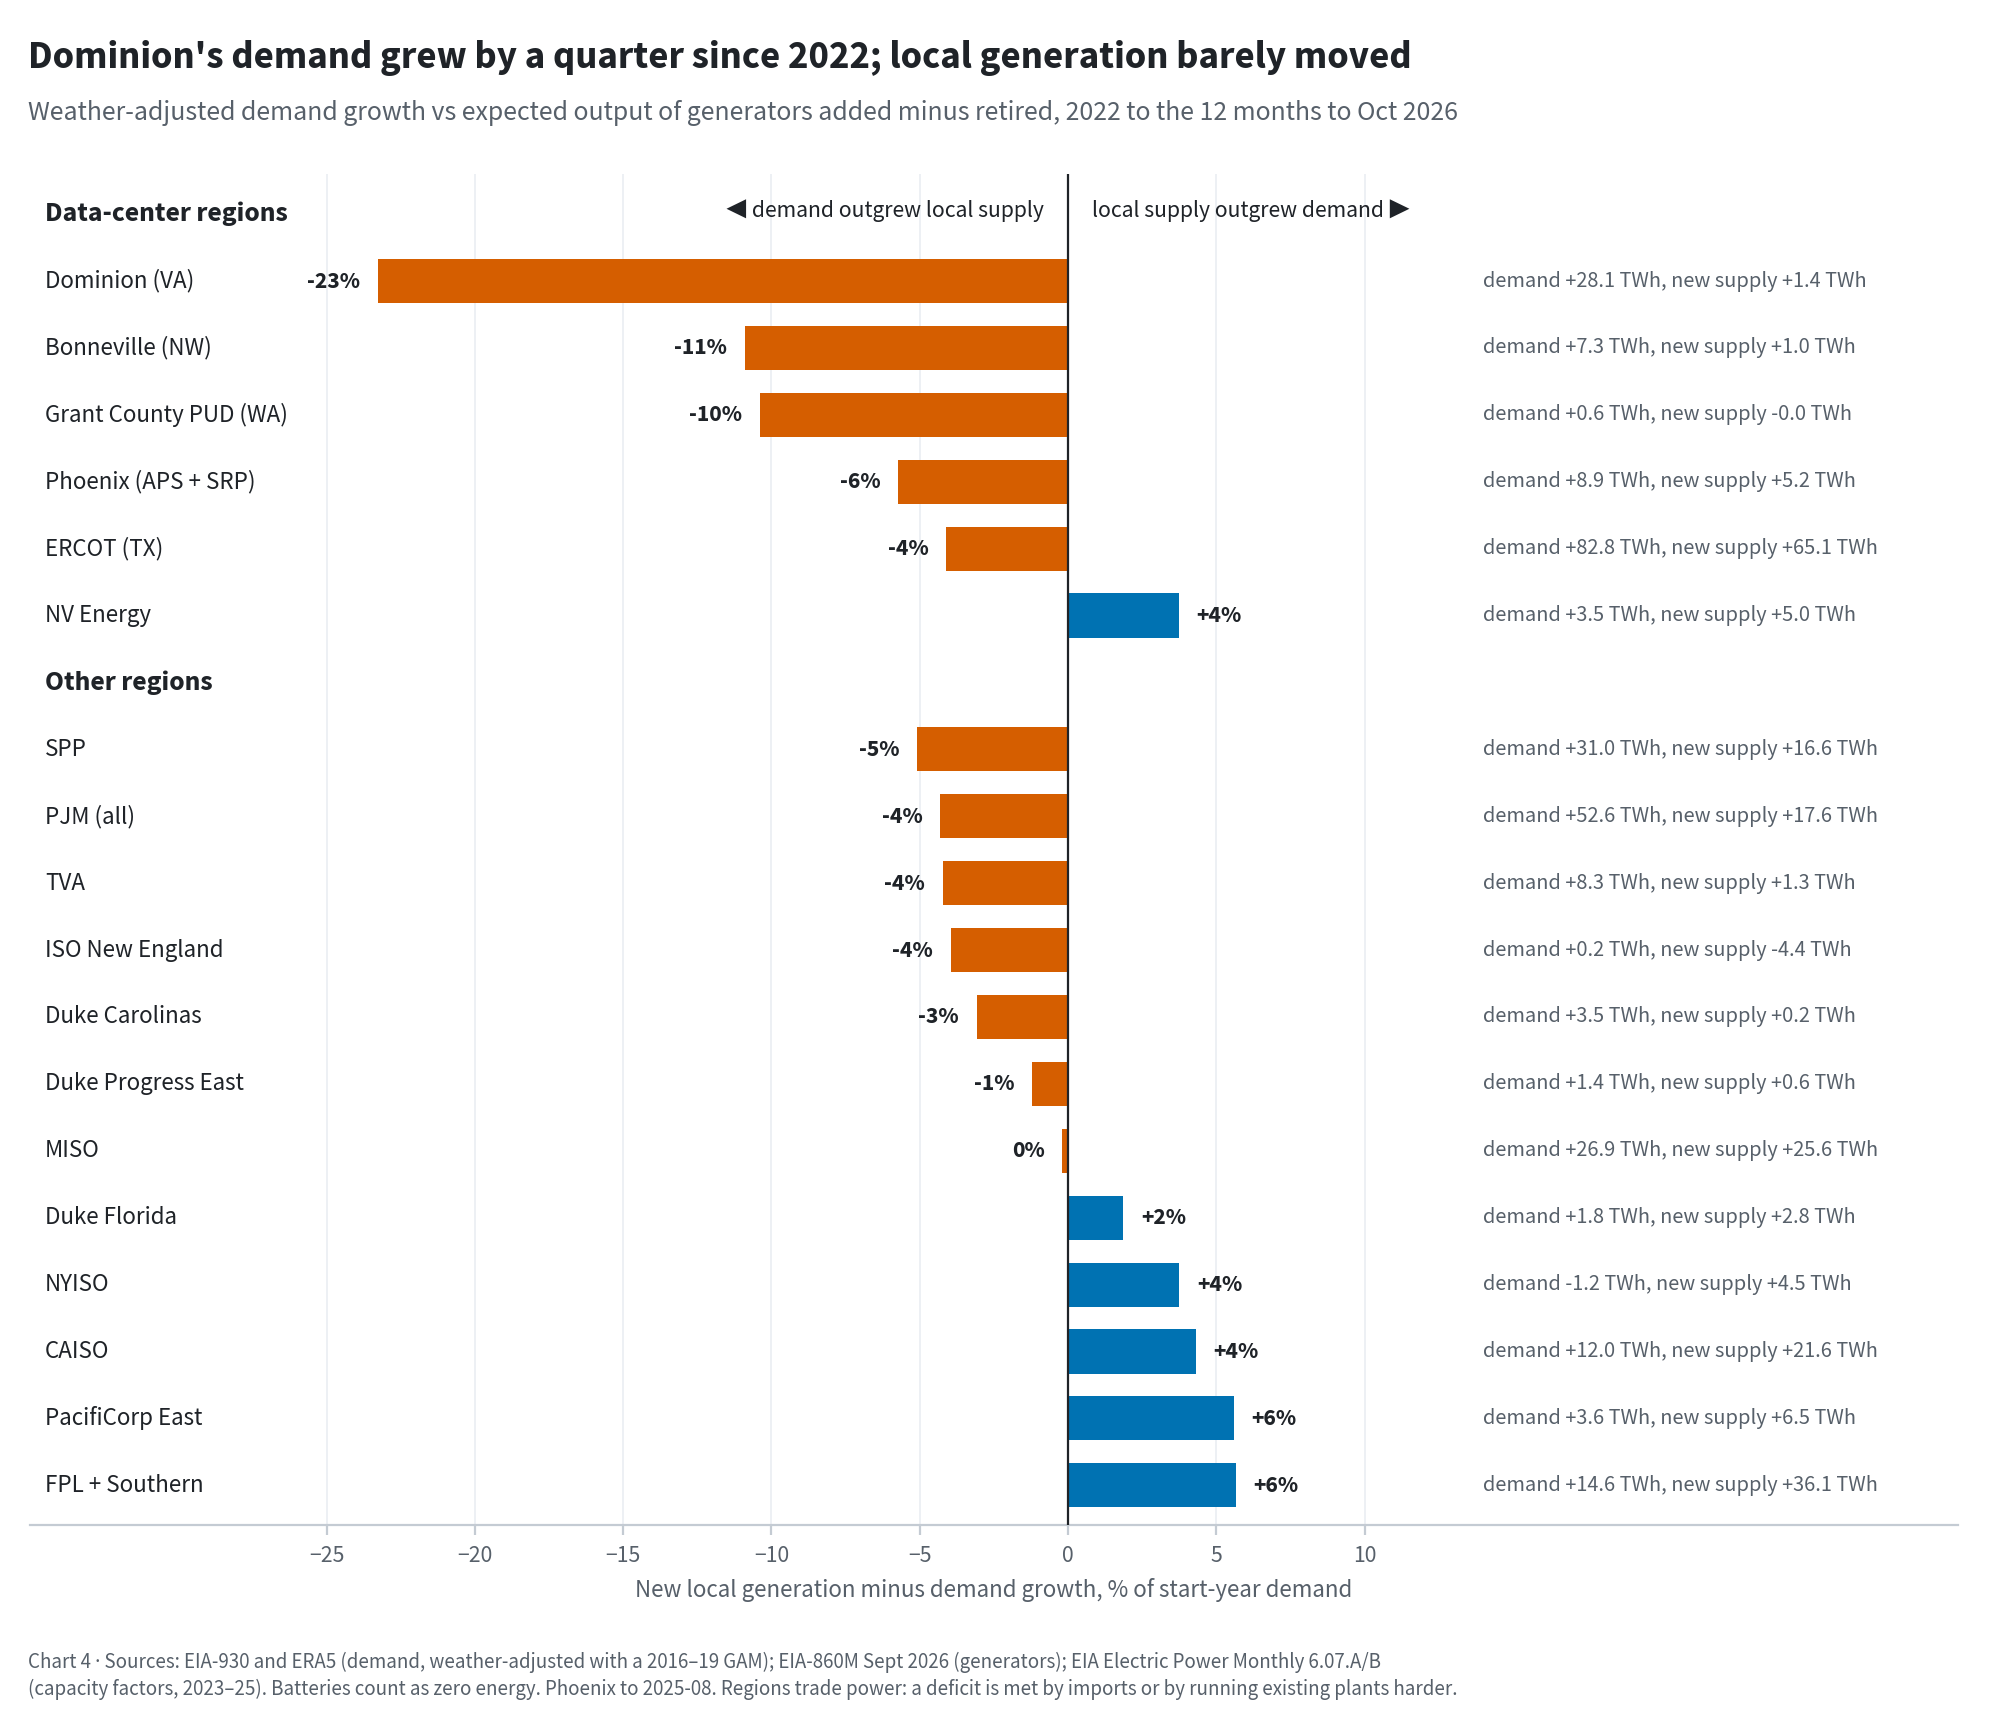

In [5]:
# Final themed figure (Prompt 16): light + dark, PNG + SVG in report/figures/
from IPython.display import Image
from glg.viz import figures as F
F.main(['chart4_supply_gap'])
Image(filename=str(F.FIGURES_DIR / 'chart4_supply_gap.png'), width=900)